# 3 — Development train / test split

The **development cohort** (complete-case, BMD-only TARGET, OSQ060/BMD-discordant rows already removed) is split **70% train / 30% test** (stratified on TARGET, `random_state=42`).

| Split | Purpose |
|-------|---------|
| **Train (~70%)** | Fit models, 10-fold CV tuning, **CTGAN training** |
| **Test (~30%)** | Internal real-data evaluation — compare training arms |
| **External 2013–14** | Never split — used only for final generalization |

Synthetic rows are **never** placed in the test or external sets.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from experiment_utils import (
    DEV_CLEAN_PATH,
    EXTERNAL_CLEAN_PATH,
    TRAIN_PATH,
    TEST_PATH,
    SPLITS_DIR,
    LABEL_COL,
    RANDOM_STATE,
    TEST_SIZE,
    ensure_dirs,
)

ensure_dirs()

## 3.1 Load cleaned cohorts

In [2]:
df_dev = pd.read_csv(DEV_CLEAN_PATH)
df_external = pd.read_csv(EXTERNAL_CLEAN_PATH)
print(f'Development complete cases: {len(df_dev)}')
print(f'External complete cases: {len(df_external)}')

Development complete cases: 2525
External complete cases: 1703


## 3.2 Stratified 70/30 split

In [3]:
train_df, test_df = train_test_split(
    df_dev,
    test_size=TEST_SIZE,
    stratify=df_dev[LABEL_COL],
    random_state=RANDOM_STATE,
)

print(f'Train: {len(train_df)} ({train_df[LABEL_COL].mean():.3f} low BMD)')
print(f'Test:  {len(test_df)} ({test_df[LABEL_COL].mean():.3f} low BMD)')

train_df.to_csv(TRAIN_PATH, index=False)
test_df.to_csv(TEST_PATH, index=False)
print(f'\nSaved:\n  {TRAIN_PATH}\n  {TEST_PATH}')

Train: 1767 (0.461 low BMD)
Test:  758 (0.460 low BMD)

Saved:
  /Users/vassilis/Documents/OP_article/DATA/splits/train.csv
  /Users/vassilis/Documents/OP_article/DATA/splits/test.csv


## 3.3 Visual check — split balance

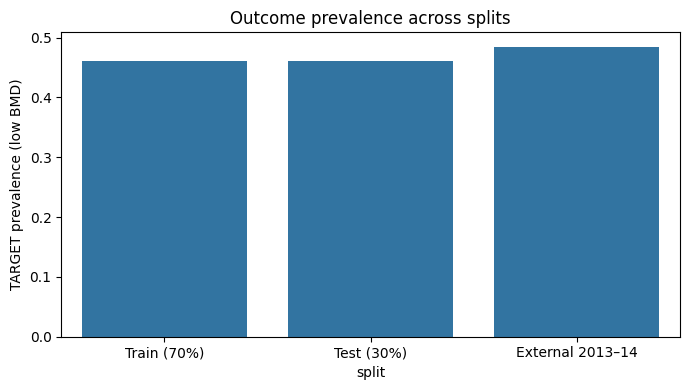

In [4]:
plot_df = pd.concat([
    train_df.assign(split='Train (70%)'),
    test_df.assign(split='Test (30%)'),
    df_external.assign(split='External 2013–14'),
])

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=plot_df, x='split', y=LABEL_COL, estimator='mean', errorbar=None, ax=ax)
ax.set_ylabel('TARGET prevalence (low BMD)')
ax.set_title('Outcome prevalence across splits')
plt.tight_layout()
plt.show()

**Next:** `4_CTGAN_SYNTHETIC.ipynb` trains CTGAN on the **train fold only** and generates a synthetic pool.